# FIFA World Cup 2026 — Linear Regression 2.1
**Goal:** Prediction of Goal_Difference for 104 matches using **exactly eight pre-match predictors**.



In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import probplot, shapiro
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge, HuberRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

## 1. Data validation and loading


In [56]:
#Data loading
file_path = "/content/Dataset2.1.xlsx"
df = pd.read_excel(file_path, sheet_name="Regression_104")
target = "Goal_Difference"

#Selecting 8 variables
features = [
    "FIFA_Points_Diff", "Squad_Age_Diff", "Mean_Caps_Diff",
    "Home_Country_Diff", "Recent_GF_Diff", "Recent_GA_Diff",
    "Recent_FTS_Diff", "Squad_Market_Value_Diff_EUR_M"
]

assert len(features) == 8 and len(set(features)) == 8
assert len(df) == 104
assert df["Match_ID"].is_unique
for column in features + [target, "Goals_A", "Goals_B"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Shape:", df.shape)
print("Missing values:\n", df[features + [target]].isna().sum())

print("Duplicate matches:", df["Match_ID"].duplicated().sum())
print("Goal difference inconsistencies:", (df["Goals_A"] - df["Goals_B"] != df[target]).sum())
print("Non-binary home-country values:", (~df["Home_Country_Diff"].isin([-1, 0, 1])).sum())
print("Non-finite feature values:", (~np.isfinite(df[features].to_numpy())).sum())

Shape: (104, 16)
Missing values:
 FIFA_Points_Diff                 0
Squad_Age_Diff                   0
Mean_Caps_Diff                   0
Home_Country_Diff                0
Recent_GF_Diff                   0
Recent_GA_Diff                   0
Recent_FTS_Diff                  0
Squad_Market_Value_Diff_EUR_M    0
Goal_Difference                  0
dtype: int64
Duplicate matches: 0
Goal difference inconsistencies: 0
Non-binary home-country values: 0
Non-finite feature values: 0


## 2. Descriptive statistics and relationships
Descriptive analysis to check how our dataset look like, and if the variables are useful for predicting goals. Correlation will help to understand the relation between variables, especially with target variables (Goals difference)

,count,mean,std,min,25%,50%,75%,max
FIFA_Points_Diff,104.0,58.049,229.994,-483.360,-116.115,72.870,230.615,510.270
Squad_Age_Diff,104.0,-0.008,1.474,-3.451,-0.975,-0.074,1.039,3.153
Mean_Caps_Diff,104.0,2.380,11.575,-37.692,-4.087,2.885,10.625,28.000
Home_Country_Diff,104.0,0.125,0.332,0.000,0.000,0.000,0.000,1.000
Recent_GF_Diff,104.0,0.112,1.007,-2.200,-0.600,0.200,0.800,2.800
Recent_GA_Diff,104.0,-0.081,0.959,-2.800,-0.600,-0.200,0.400,2.600
Recent_FTS_Diff,104.0,-0.013,0.271,-0.600,-0.200,0.000,0.200,0.600
Squad_Market_Value_Diff_EUR_M,104.0,76.757,529.294,-1341.200,-213.917,58.375,365.790,1460.570
Goal_Difference,104.0,0.500,2.019,-4.000,-1.000,0.000,2.000,6.000


Correlations: 
 FIFA_Points_Diff                 0.641
Recent_GF_Diff                   0.442
Squad_Market_Value_Diff_EUR_M    0.415
Home_Country_Diff                0.123
Mean_Caps_Diff                   0.119
Squad_Age_Diff                  -0.054
Recent_GA_Diff                  -0.350
Recent_FTS_Diff                 -0.421
Name: Goal_Difference, dtype: float64


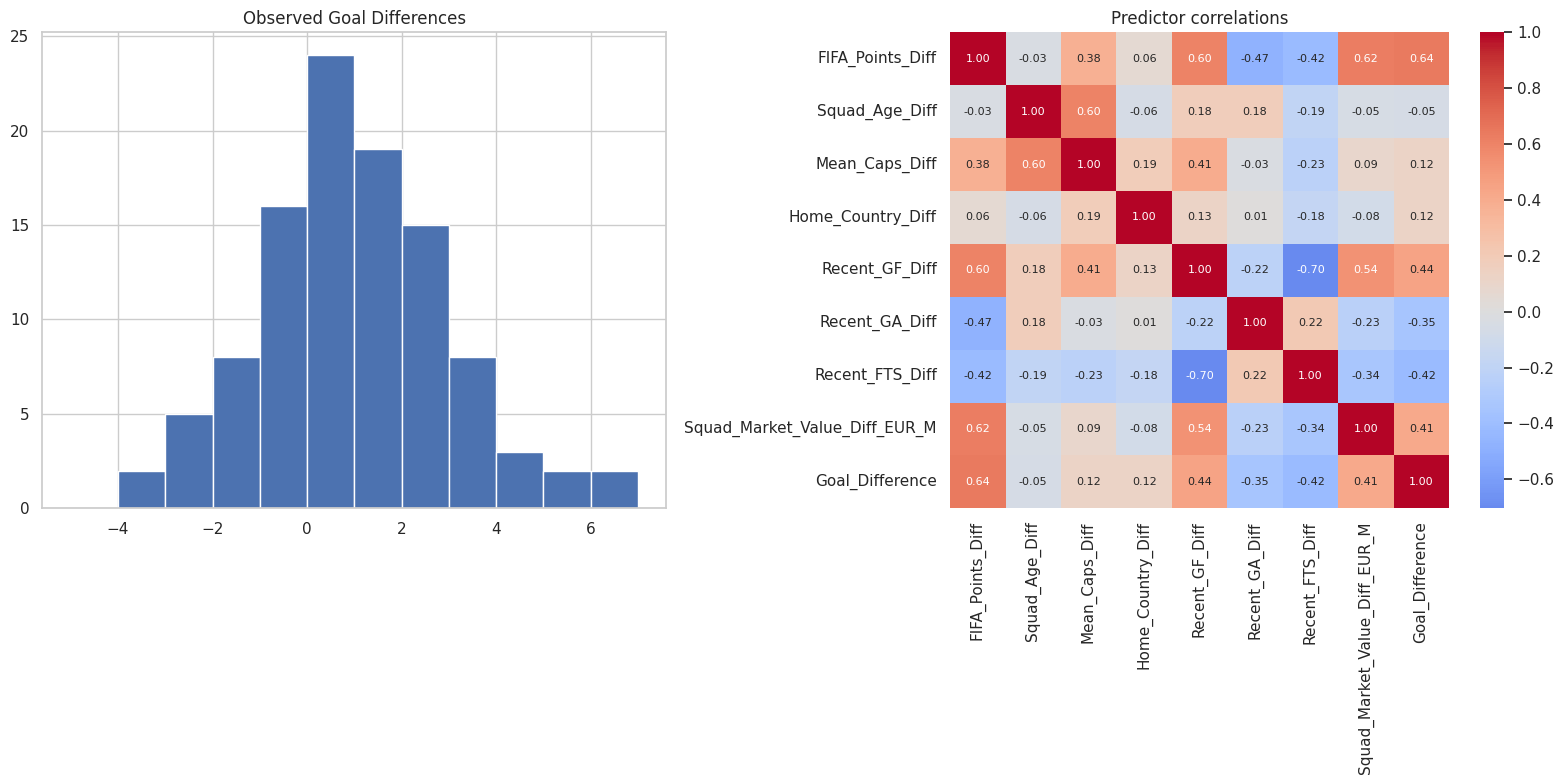

In [57]:
display(df[features + [target]].describe().T.round(3))
corr = df[features + [target]].corr()

print("Correlations: \n", corr[target].drop(target).sort_values(ascending=False).round(3))
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].hist(df[target], bins=range(int(df[target].min())-1, int(df[target].max())+2)); axes[0].set_title("Observed Goal Differences")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1], annot_kws={"size":8})
axes[1].set_title("Predictor correlations")
plt.tight_layout(); plt.show()

## 3. Train/test split
Randomly divided into train data - 80% (Used for implementing the multiple linear regression model) and test data - 20% (Used to test how good the model predicts goals for unseen matches)

In [58]:
X = df[features].copy()
y = df[target].copy()
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.20, random_state=42, shuffle=True)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("Training rows:", len(X_train), "Test rows:", len(X_test))

Training rows: 83 Test rows: 21


## 4. Five-fold cross-validation and model comparison
Compare and implement Linear Regression along with other models

,Model,Cross Validation RMSE Mean,Cross Validation RMSE SD,Cross Validation MAE Mean,Cross Validation R2 Mean
0,Original Linear Regression,1.606,0.254,1.316,0.322
2,Ridge Linear Regression,1.607,0.229,1.293,0.325
1,Yeo-Johnson + Linear Regression,1.613,0.246,1.319,0.317
3,Huber Linear Regression,1.631,0.289,1.342,0.294
4,Random Forest (benchmark),1.645,0.268,1.312,0.299
5,Gradient Boosting (benchmark),1.744,0.204,1.354,0.202


Selected LINEAR model by training-only Cross Validation: Original Linear Regression


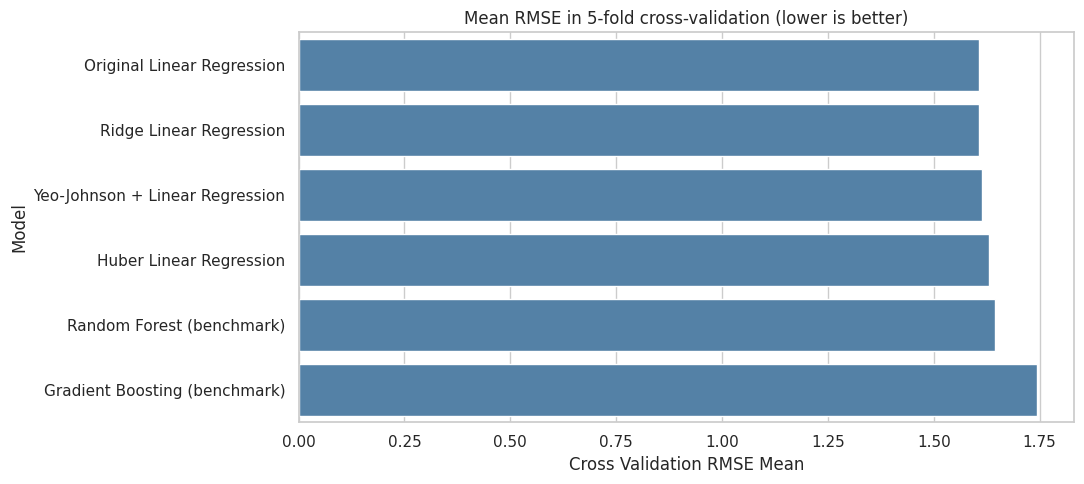

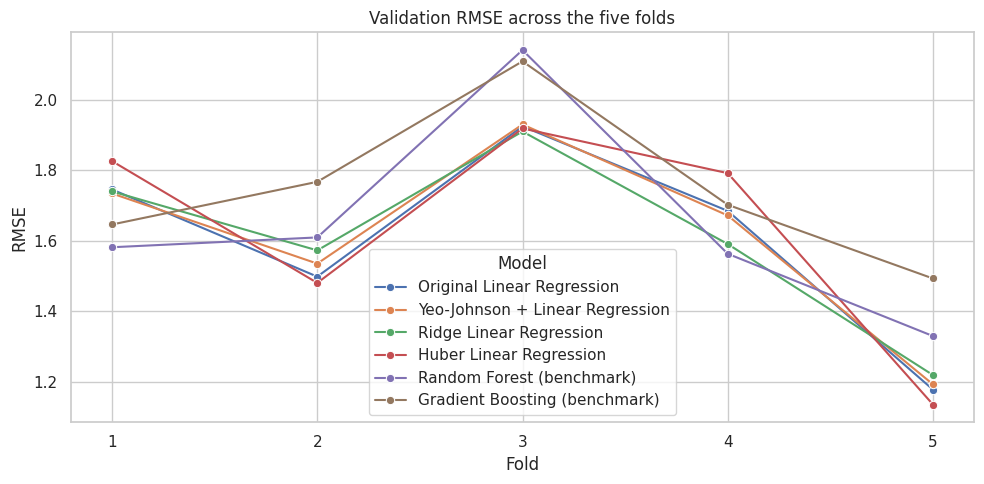

In [59]:
models = {
    "Original Linear Regression": Pipeline([("scale", StandardScaler()), ("regression", LinearRegression())]),
    "Yeo-Johnson + Linear Regression": Pipeline([("power", PowerTransformer(method="yeo-johnson")), ("regression", LinearRegression())]),
    "Ridge Linear Regression": Pipeline([("scale", StandardScaler()), ("regression", Ridge(alpha=10))]),
    "Huber Linear Regression": Pipeline([("scale", StandardScaler()), ("regression", HuberRegressor(max_iter=2000))]),
    "Random Forest (benchmark)": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42),
    "Gradient Boosting (benchmark)": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
fold_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring={"rmse":"neg_root_mean_squared_error", "mae":"neg_mean_absolute_error", "r2":"r2"})
    rmse = -scores["test_rmse"]
    cv_rows.append({"Model":name, "Cross Validation RMSE Mean":rmse.mean(), "Cross Validation RMSE SD":rmse.std(),
                    "Cross Validation MAE Mean":(-scores["test_mae"]).mean(), "Cross Validation R2 Mean":scores["test_r2"].mean()})
    for i in range(5): fold_rows.append({"Model":name,"Fold":i+1,"RMSE":rmse[i]})
cv_results = pd.DataFrame(cv_rows).sort_values("Cross Validation RMSE Mean")
display(cv_results.round(3))
linear_names = [name for name in models if "benchmark" not in name]
selected_name = cv_results[cv_results["Model"].isin(linear_names)].iloc[0]["Model"]
print("Selected LINEAR model by training-only Cross Validation:", selected_name)
plt.figure(figsize=(11,5))
sns.barplot(data=cv_results, x="Cross Validation RMSE Mean", y="Model", color="steelblue")
plt.title("Mean RMSE in 5-fold cross-validation (lower is better)")
plt.tight_layout(); plt.show()
plt.figure(figsize=(10,5))
sns.lineplot(data=pd.DataFrame(fold_rows), x="Fold", y="RMSE", hue="Model", marker="o")
plt.xticks([1,2,3,4,5]); plt.title("Validation RMSE across the five folds")
plt.tight_layout(); plt.show()


## 5. Test evaluation
Evaluating the trained regression model test data to predict goals difference for FIFA World Cup 2026

In [60]:
test_rows = []
predictions = {}
fitted = {}

for name, model in models.items():
    trained_data = clone(model).fit(X_train, y_train)
    predicted = trained_data.predict(X_test)
    predictions[name] = predicted
    fitted[name] = trained_data
    test_rows.append({"Models":name, "MAE":mean_absolute_error(y_test,predicted),
                      "RMSE":np.sqrt(mean_squared_error(y_test,predicted)), "R2":r2_score(y_test,predicted)})
baseline = np.repeat(y_train.mean(), len(y_test))
test_rows.append({"Model":"Training mean baseline", "MAE":mean_absolute_error(y_test,baseline),
                  "RMSE":np.sqrt(mean_squared_error(y_test,baseline)), "R2":r2_score(y_test,baseline)})
test_results = pd.DataFrame(test_rows).sort_values("RMSE")
display(test_results.round(3))

#Printing best model among all
print("Best model:", selected_name)

,Models,MAE,RMSE,R2,Model
0,Original Linear Regression,1.034,1.479,0.382,NaN
1,Yeo-Johnson + Linear Regression,1.052,1.510,0.355,NaN
3,Huber Linear Regression,1.079,1.515,0.351,NaN
2,Ridge Linear Regression,1.068,1.521,0.346,NaN
4,Random Forest (benchmark),1.188,1.551,0.320,NaN
5,Gradient Boosting (benchmark),1.165,1.560,0.312,NaN
6,NaN,1.518,1.900,-0.020,Training mean baseline


Best model: Original Linear Regression


## 6. Predictions, large errors and residual diagnostics



,Match_ID,Team_A,Team_B,Goal_Difference,Predicted,Residual,Absolute Error
26,27,Canada,Qatar,6,1.968,4.032,4.032
93,94,USA,Belgium,-3,0.591,-3.591,3.591
33,34,Ecuador,Curaçao,0,2.041,-2.041,2.041
31,32,USA,Australia,2,0.414,1.586,1.586
77,78,Ivory Coast,Norway,-1,0.459,-1.459,1.459
53,54,South Africa,South Korea,1,-0.293,1.293,1.293
12,13,Saudi Arabia,Uruguay,0,-1.269,1.269,1.269
30,31,Turkey,Paraguay,-1,0.177,-1.177,1.177
18,19,Argentina,Algeria,3,2.038,0.962,0.962
91,92,Mexico,England,-1,-0.215,-0.785,0.785


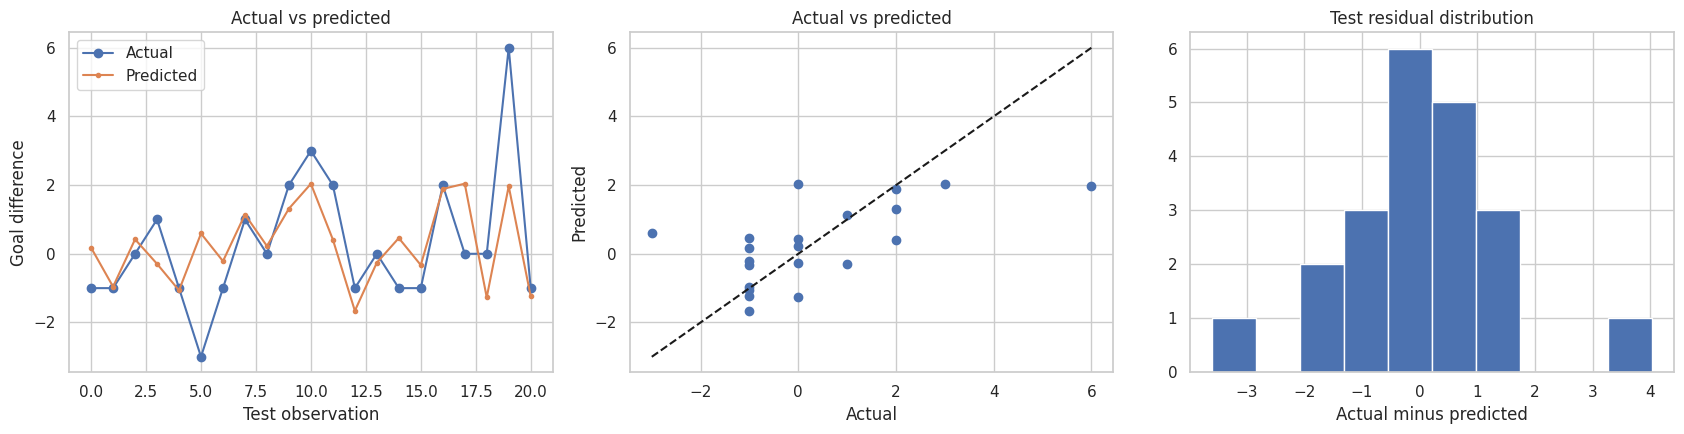

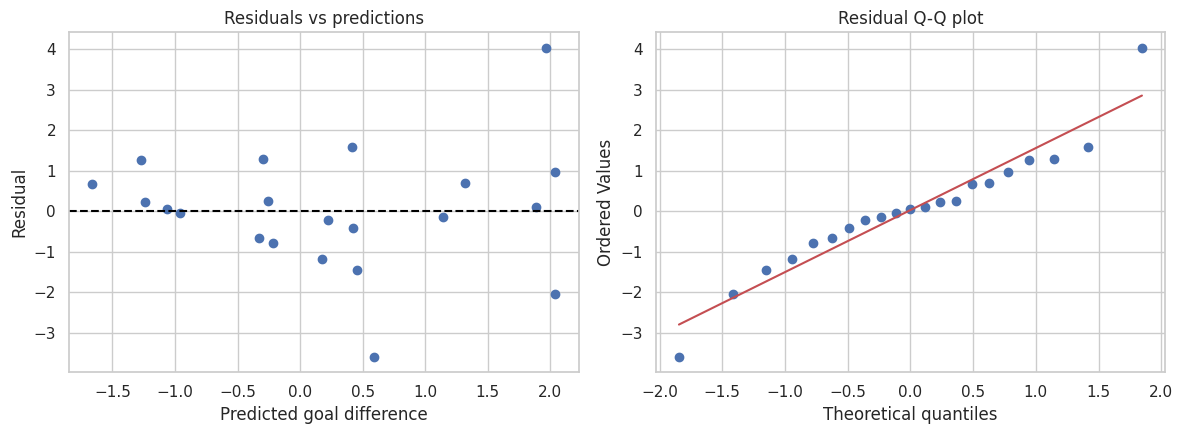

Shapiro-Wilk p-value on test residuals: 0.338


In [61]:
pred = predictions[selected_name]
actual = y_test.to_numpy()
residuals = actual - pred
review = df.iloc[test_idx][["Match_ID","Team_A","Team_B",target]].copy()
review["Predicted"] = pred
review["Residual"] = residuals
review["Absolute Error"] = np.abs(residuals)

display(review.sort_values("Absolute Error",ascending=False).head(10).round(3))
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
axes[0].plot(actual,"o-",label="Actual"); axes[0].plot(pred,".-",label="Predicted")
axes[0].set(title="Actual vs predicted", xlabel="Test observation",ylabel="Goal difference"); axes[0].legend()
axes[1].scatter(actual,pred)
lo=min(actual.min(),pred.min()); hi=max(actual.max(),pred.max())
axes[1].plot([lo,hi],[lo,hi],"k--")
axes[1].set(title="Actual vs predicted",xlabel="Actual",ylabel="Predicted")
axes[2].hist(residuals,bins=10)
axes[2].set(title="Test residual distribution",xlabel="Actual minus predicted")
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].scatter(pred,residuals); axes[0].axhline(0,ls="--",c="black")
axes[0].set(title="Residuals vs predictions",xlabel="Predicted goal difference",ylabel="Residual")
probplot(residuals,dist="norm",plot=axes[1]); axes[1].set_title("Residual Q-Q plot")
plt.tight_layout();plt.show()
print("Shapiro-Wilk p-value on test residuals:",round(shapiro(residuals).pvalue,4))


## 7. Predictor importance and collinearity


Training out-of-fold RMSE: 1.63


,Feature,MAE Increase,SD
0,FIFA_Points_Diff,0.684,0.090
2,Mean_Caps_Diff,0.093,0.035
6,Recent_FTS_Diff,0.063,0.043
5,Recent_GA_Diff,0.036,0.018
1,Squad_Age_Diff,0.021,0.018
4,Recent_GF_Diff,0.012,0.012
7,Squad_Market_Value_Diff_EUR_M,0.000,0.002
3,Home_Country_Diff,-0.003,0.011


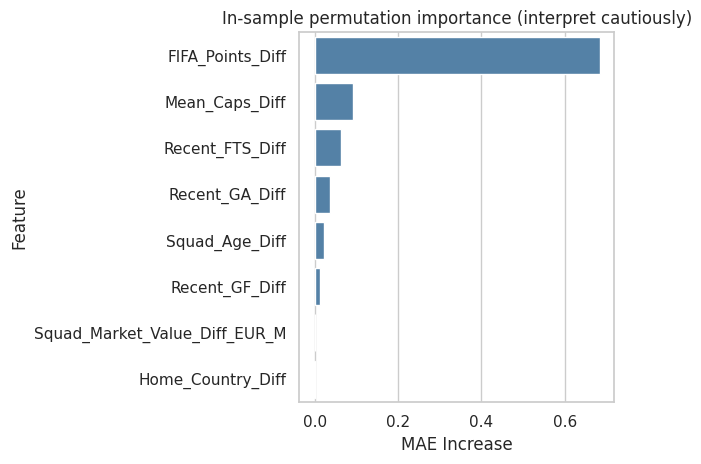

,Feature,VIF
4,Recent_GF_Diff,3.37
0,FIFA_Points_Diff,3.02
2,Mean_Caps_Diff,2.66
6,Recent_FTS_Diff,2.57
1,Squad_Age_Diff,2.16
7,Squad_Market_Value_Diff_EUR_M,1.97
5,Recent_GA_Diff,1.42
3,Home_Country_Diff,1.14


In [62]:
from sklearn.model_selection import cross_val_predict
cv_pred = cross_val_predict(models[selected_name], X_train, y_train, cv=cv)
print("Training out-of-fold RMSE:", round(np.sqrt(mean_squared_error(y_train,cv_pred)),3))
# Permutation importance on training data: descriptive only (in-sample fit), not final validation.
perm = permutation_importance(fitted[selected_name], X_train, y_train,
                              n_repeats=20, random_state=42, scoring="neg_mean_absolute_error")
importance = pd.DataFrame({"Feature":features,"MAE Increase":perm.importances_mean,
                            "SD":perm.importances_std}).sort_values("MAE Increase",ascending=False)
display(importance.round(3))
sns.barplot(data=importance,x="MAE Increase",y="Feature",color="steelblue")
plt.title("In-sample permutation importance (interpret cautiously)");plt.tight_layout();plt.show()
X_vif = sm.add_constant(X_train)
vif = pd.DataFrame({"Feature":features, "VIF":[variance_inflation_factor(X_vif.values,i+1) for i in range(len(features))]})
display(vif.sort_values("VIF",ascending=False).round(2))

## 8. Prediction for Goal difference

In [63]:

# Enter details for a new match
new_match = pd.DataFrame({
    "FIFA_Points_Diff": [230],
    "Squad_Age_Diff": [7],
    "Mean_Caps_Diff": [10],
    "Home_Country_Diff": [0],
    "Recent_GF_Diff": [4],
    "Recent_GA_Diff": [-2],
    "Recent_FTS_Diff": [-0.2],
    "Squad_Market_Value_Diff_EUR_M": [350]
})

# Select the Original Linear Regression
best_model = models[selected_name]

# Train the model
best_model.fit(X_train, y_train)

# Predict goal difference
predicted_difference = best_model.predict(new_match[features])[0]

# Display prediction
print("Predicted goal difference:", round(predicted_difference, 2))
print("Rounded goal difference:", round(predicted_difference))


Predicted goal difference: 1.98
Rounded goal difference: 2
